In [2]:
from torchvision.datasets import FashionMNIST
from dataset import load_raw_dataset, create_dataloader
import config
import MyLog
from utility import set_seed
from MyVisualize import show_batch, writer, show_loss_acc, show_predictions
from model import FashionCNN, training_phase
import torch.nn as nn
import torch.optim as optim

print(config.ROOT_PATH)

/home/notworle/nonvintage/gitvanhub/Deeplearning-UTH/labs/lab1/main


# Set up


In [3]:
MyLog.log_creation()
set_seed()

================================ Configration ================================
Device              : cuda
GPU                 : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM                : 8.6 GB
Seed                : 248
Workers             : 8
Batch size          : 32



# Problem define
FashionMNIST sinh ra để thay thế MNIST làm benchmark. MNIST quá dễ (CNN đơn giản đạt ~99%, thậm chí model tuyến tính cũng ~92%), nên không còn phân biệt được model tốt hay dở. Bài toán được định nghĩa là phân loại ảnh xám 28×28 vào 10 loại sản phẩm thời trang, giữ nguyên format MNIST để chỉ cần đổi đường dẫn là chạy.



# Data collection
- Nguồn là ảnh sản phẩm trên website Zalando, mỗi sản phẩm lấy 1 ảnh mặt trước (thumbnail JPEG khoảng 762×1000).
- Tổng 70.000 sản phẩm, 10 lớp, mỗi lớp 7.000 ảnh. Chia 60.000 train / 10.000 test, cân bằng lớp.
- Nhãn lấy từ phân loại có sẵn của Zalando (silhouette code do đội chuyên môn của họ gán). Không phải crowdsource.

# Data cleaning
Họ không “clean” kiểu xóa outlier hay điền missing. Thực chất là một pipeline chuyển ảnh gốc thành 28×28:
1. Chuyển sang PNG
2. Cắt viền thừa có màu gần giống pixel góc
3. Resize cạnh dài về 28
4. Làm nét bằng bộ lọc Gaussian
5. Pad cạnh ngắn về 28, đặt vật thể vào giữa
6. Đảo cường độ (nền đen, vật thể sáng, giống MNIST)
7. Chuyển sang grayscale 8-bit

Vì vậy dữ liệu bạn tải về đã sạch: không có missing, không có ảnh sai kích thước. Việc cần làm là kiểm tra lại (shape, dtype, phân bố lớp, vài ảnh mẫu) chứ không phải làm sạch.

# Load FashionMNIST dataset.

In [4]:
# Load raw dataset
v_train_dataset, v_test_dataset = load_raw_dataset(FashionMNIST)
MyLog.dataset_log(FashionMNIST, v_train_dataset, v_test_dataset)


# Dataloader
v_train_dataloader, v_test_dataloader = create_dataloader(v_train_dataset, v_test_dataset)
MyLog.dataloader_log(v_train_dataset, v_test_dataset)

Dataset name        : <class 'torchvision.datasets.mnist.FashionMNIST'>
Training dataset s..: 60000
Test dataset size   : 10000
Label index         : 9
Label name          : Ankle boot
Image shape         : torch.Size([1, 28, 28])
Min - max image     : -1.0, 1.0

Number of train data: 60000
Number of test datal: 10000


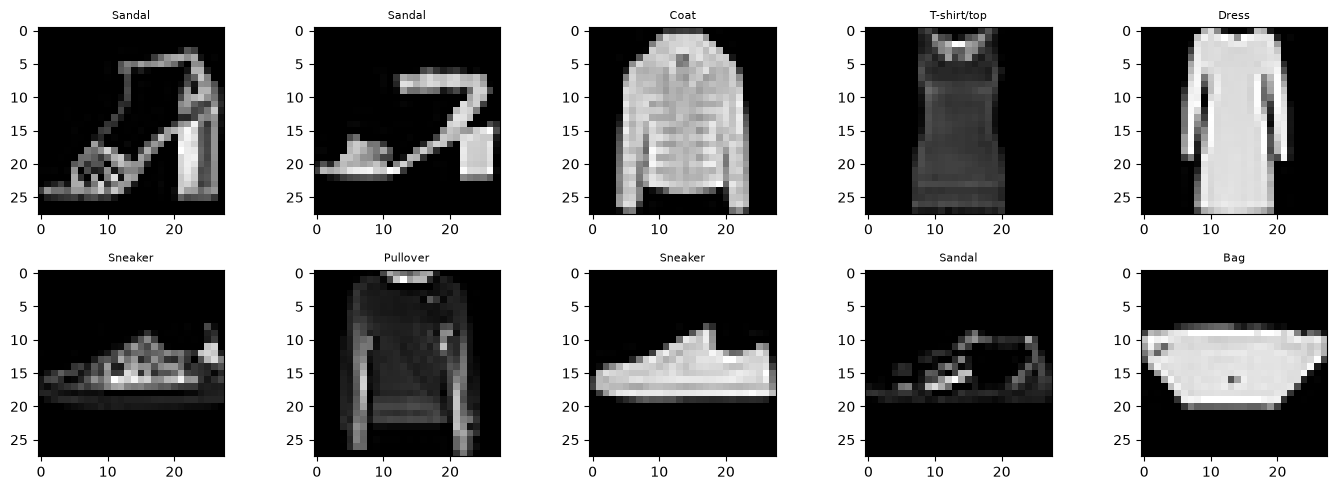

In [5]:
# Visual batch
show_batch(FashionMNIST, v_train_dataloader)

# Build model

In [6]:
model = FashionCNN().to(config.DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config.LR)
best_val = 0

print(model)

FashionCNN(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Line

# Training


In [7]:
# Training phase
list_metric_train_epoch, list_metric_eval_epoch = training_phase(
    model,
    loss_func,
    optimizer,
    v_train_dataloader,
    v_test_dataloader,
    30,
    config.SAVE_FASHION_CNN_WEIGHT
)

Resume from         : /home/notworle/nonvintage/gitvanhub/Deeplearning-UTH/labs/lab1/main/weights/FASHION_MNIST_CNN.pt
Accuracy            : 0.8681


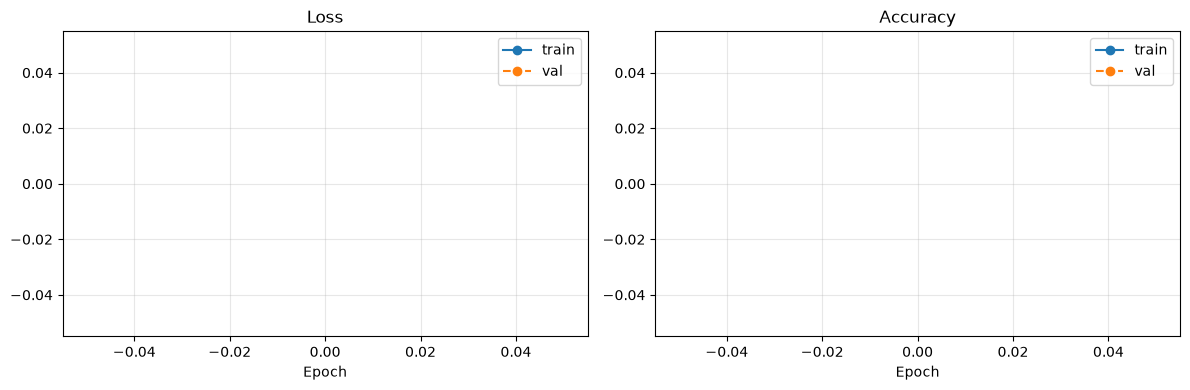

In [8]:
show_loss_acc(list_metric_train_epoch, list_metric_eval_epoch)


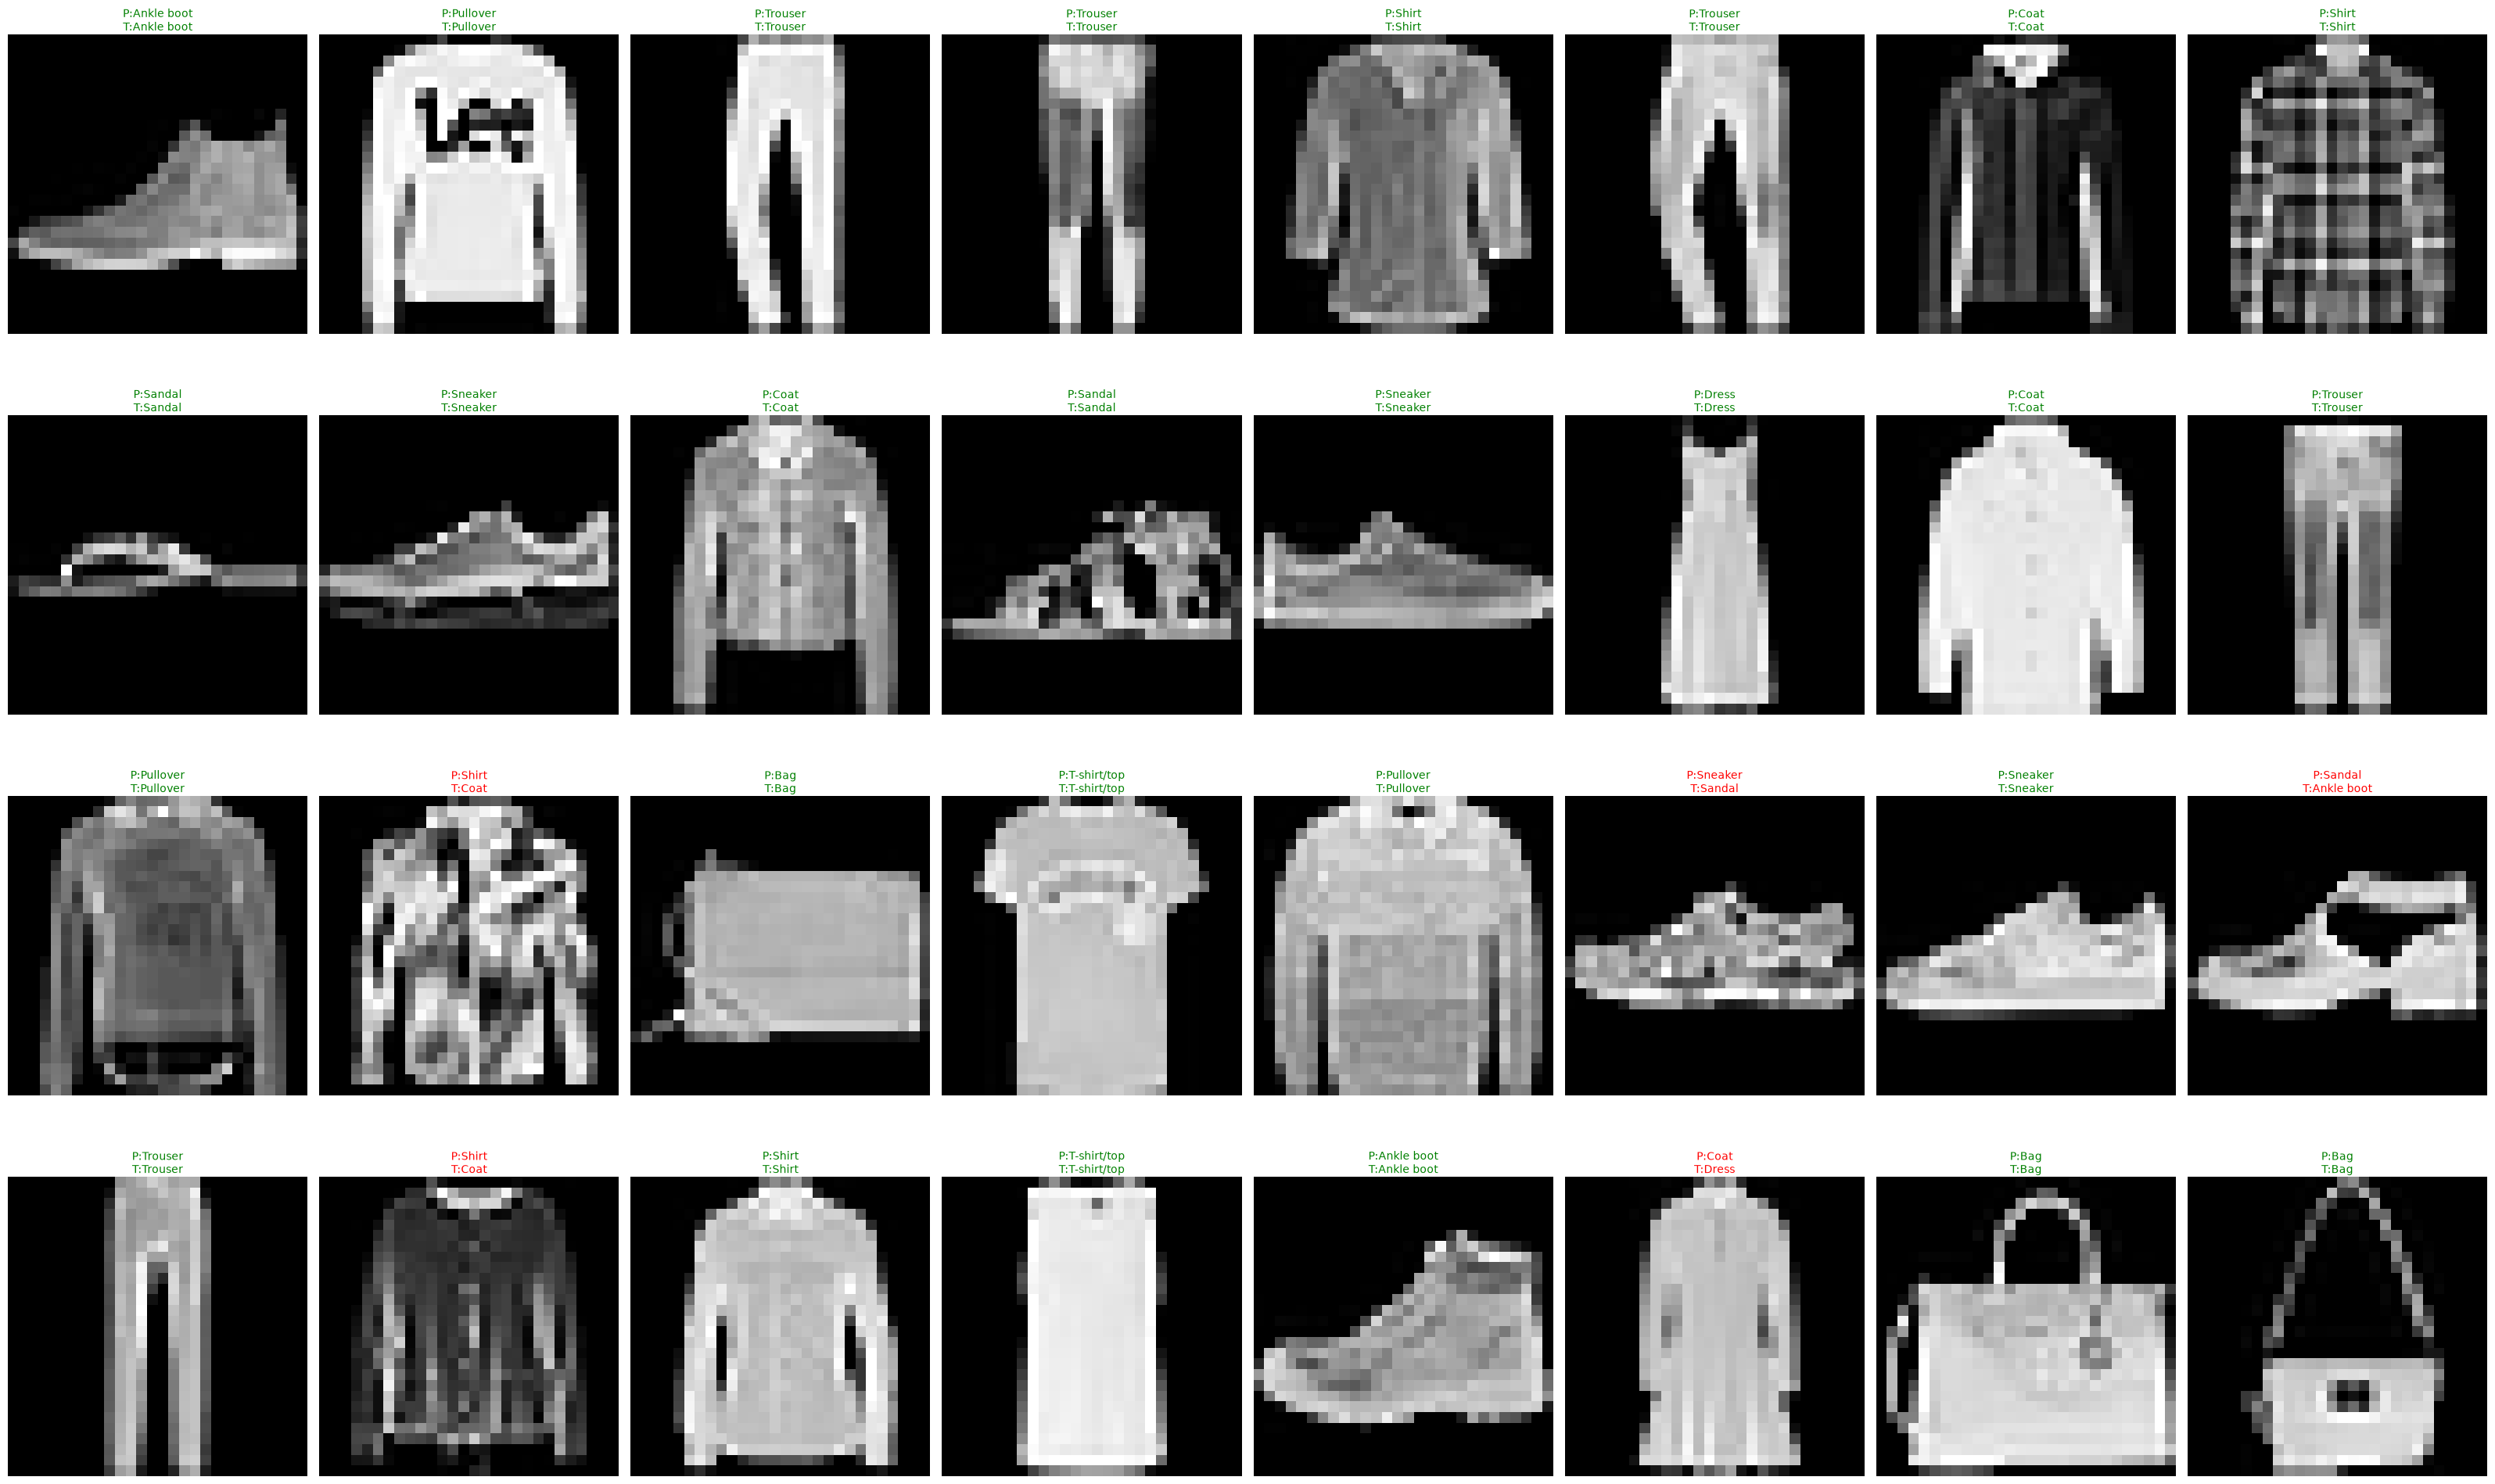

In [9]:
# Visualize
show_predictions(model, v_test_dataloader, FashionMNIST)
